In [1]:
# =============================================================================
# CS-781 Phase 1 — Architecture #3: Gated Cross-Attention Encoder-Decoder Transformer
#
# Inspired by (cited, not imported): the original Transformer encoder-decoder
# (Vaswani et al., 2017) — a generic architecture family, not a named LLM.
#
# OUR OWN MODIFICATION: instead of a fixed additive cross-attention residual
# (standard in the original design), each decoder token has a LEARNED SIGMOID
# GATE controlling how much weight its cross-attention-to-encoder output gets.
# Rationale: in legal continuation, the model must decide per-token how much
# to anchor to specific facts in the source prompt (party names, statute
# numbers, case specifics) vs. generate fluent continuation independently —
# a fixed cross-attention weight can't adapt that per-token; a learned gate can.
#
# Also structurally different from Arch #1 (causal decoder-only, RoPE/SwiGLU)
# and Arch #2 (local-window + persistent memory): this is bidirectional
# encoder + causal decoder + cross-attention, trained as SPAN CONTINUATION
# (encoder sees the prompt, decoder generates the continuation) — matching
# the actual test task directly, rather than generic next-token LM chunking.
#
# Uses PyTorch's fused scaled_dot_product_attention throughout (fast,
# memory-efficient) — deliberately avoiding Arch #2's manual dense
# score-matrix mistake that caused the earlier slowdowns.
#
# Run in Kaggle: paste each "# %%" block as its own cell, in order.
# =============================================================================

In [1]:
# %% [1] Imports & HF login
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

import json, math, random, time, zipfile
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from kaggle_secrets import UserSecretsClient
from huggingface_hub import login, hf_hub_download

user_secrets = UserSecretsClient()
HF_TOKEN = user_secrets.get_secret("HF")
os.environ["HF_TOKEN"] = HF_TOKEN
login(token=HF_TOKEN)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"
TEST_FILE = "Phase_1_Pretraining/Test/test.json"

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


Device: cuda


In [5]:
# %% [2] Config
SEED = 42
random.seed(SEED); torch.manual_seed(SEED)

# !!! EDIT THIS to the dataset slug Kaggle gave your committed Arch #1 notebook's output.
ARTIFACT_PATH = "/kaggle/input/datasets/akashmalgav2/akashrm2"

ENC_LEN = 512          # encoder sees up to this many tokens of the "prompt" chunk
DEC_LEN = 160          # decoder generates up to this many tokens of "continuation"
                        # (test needs 128 words; 160 tokens gives headroom)
N_LAYER_ENC = 6
N_LAYER_DEC = 6
N_HEAD = 12
N_EMBD = 576            # kept same width as Arch #1/#2 for comparability
FFN_MULT = 4
DROPOUT = 0.1

BATCH_SIZE = 16          # full attention at these (short) lengths is cheap — can afford more
GRAD_ACCUM = 2           # effective batch = 32, same as Arch #2
LR = 3e-4
MIN_LR = 3e-5
WARMUP_STEPS = 300
MAX_STEPS = 6000
EVAL_EVERY = 500
LOG_EVERY = 50

TARGET_GEN_WORDS = 128
TEMPERATURE = 0.7
TOP_P = 0.95
NO_REPEAT_NGRAM = 3      # lesson learned from Arch #2 — bake this in from the start

OUTPUT_DIR = "/kaggle/working/cs781_phase1_arch3"
os.makedirs(OUTPUT_DIR, exist_ok=True)
CKPT_PATH = os.path.join(OUTPUT_DIR, "model.pt")
PREDICTION_PATH = os.path.join(OUTPUT_DIR, "prediction.json")
SUBMISSION_ZIP = os.path.join(OUTPUT_DIR, "submission_phase1_arch3.zip")
LOSS_PLOT_PATH = os.path.join(OUTPUT_DIR, "loss.png")

In [6]:
# %% [3] Load the REUSED tokenizer (same as Arch #1 / #2 — no retraining)
with open(f"{ARTIFACT_PATH}/legal_bpe.json", "r", encoding="utf-8") as f:
    _tok = json.load(f)
vocab = _tok["itos"]
merges = [tuple(p) for p in _tok["merges"]]
token_to_id = {tok: i for i, tok in enumerate(vocab)}
merges_rank = {p: i for i, p in enumerate(merges)}
PAD_ID = token_to_id["<pad>"]
UNK_ID = token_to_id["<unk>"]
BOS_ID = token_to_id["<s>"]
EOS_ID = token_to_id["</s>"]
ACTUAL_VOCAB_SIZE = len(vocab)
EOW = "\u0100"

def word_to_symbols(word):
    return tuple(chr(b) for b in word.encode("utf-8", "ignore")) + (EOW,)

def bpe_encode_word(word):
    symbols = list(word_to_symbols(word))
    while len(symbols) > 1:
        pairs = [(symbols[i], symbols[i + 1]) for i in range(len(symbols) - 1)]
        ranked = [(merges_rank[p], p) for p in pairs if p in merges_rank]
        if not ranked:
            break
        _, best = min(ranked)
        new_symbols, i = [], 0
        while i < len(symbols):
            if i < len(symbols) - 1 and symbols[i] == best[0] and symbols[i + 1] == best[1]:
                new_symbols.append(best[0] + best[1]); i += 2
            else:
                new_symbols.append(symbols[i]); i += 1
        symbols = new_symbols
    return symbols

def encode(text, add_bos=True, add_eos=True):
    ids = [BOS_ID] if add_bos else []
    for w in text.split():
        for sym in bpe_encode_word(w):
            ids.append(token_to_id.get(sym, UNK_ID))
    if add_eos:
        ids.append(EOS_ID)
    return ids

def decode(ids):
    byte_buf = []
    for i in ids:
        if i in (PAD_ID, BOS_ID, EOS_ID, UNK_ID):
            continue
        tok = vocab[i]
        for ch in tok:
            if ch == EOW:
                byte_buf.append(0x20)
            elif ord(ch) <= 255:
                byte_buf.append(ord(ch))
    return bytes(byte_buf).decode("utf-8", errors="replace").strip()

print("Loaded tokenizer. Vocab size:", ACTUAL_VOCAB_SIZE)
print("Sanity check:", decode(encode("The petitioner filed the present appeal.")))

Loaded tokenizer. Vocab size: 32000
Sanity check: The petitioner filed the present appeal.


In [7]:
# %% [4] Reconstruct per-document sequences & build (encoder_input, decoder_target) pairs
# train_tokens.pt / val_tokens.pt are a FLAT concatenated stream (BOS...EOS BOS...EOS ...).
# Split on EOS_ID to recover individual documents, then for each document use the
# first ENC_LEN tokens as the encoder "prompt" and the next DEC_LEN tokens as the
# decoder "continuation" target — directly mirroring the test task.
flat_train = torch.load(f"{ARTIFACT_PATH}/train_tokens.pt").tolist()
flat_val = torch.load(f"{ARTIFACT_PATH}/val_tokens.pt").tolist()

def split_into_documents(flat_ids):
    docs, cur = [], []
    for t in flat_ids:
        cur.append(t)
        if t == EOS_ID:
            docs.append(cur)
            cur = []
    if cur:
        docs.append(cur)
    return docs

train_docs = split_into_documents(flat_train)
val_docs = split_into_documents(flat_val)
print(f"Recovered {len(train_docs):,} train docs, {len(val_docs):,} val docs")

def build_pairs(docs, enc_len, dec_len, min_total=64):
    pairs = []
    for doc in docs:
        if len(doc) < min_total:
            continue
        enc_ids = doc[:enc_len]
        dec_ids = doc[enc_len:enc_len + dec_len]
        if len(dec_ids) < 8:   # need at least a handful of continuation tokens
            continue
        pairs.append((enc_ids, dec_ids))
    return pairs

train_pairs = build_pairs(train_docs, ENC_LEN, DEC_LEN)
val_pairs = build_pairs(val_docs, ENC_LEN, DEC_LEN)
print(f"Train pairs: {len(train_pairs):,} | Val pairs: {len(val_pairs):,}")

class Seq2SeqDataset(Dataset):
    def __init__(self, pairs, enc_len, dec_len, pad_id):
        self.pairs = pairs
        self.enc_len = enc_len
        self.dec_len = dec_len
        self.pad_id = pad_id

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        enc_ids, dec_ids = self.pairs[idx]
        enc = enc_ids + [self.pad_id] * (self.enc_len - len(enc_ids))
        enc_mask = [1] * len(enc_ids) + [0] * (self.enc_len - len(enc_ids))

        dec_in = dec_ids[:-1] if len(dec_ids) > 1 else dec_ids
        dec_out = dec_ids[1:] if len(dec_ids) > 1 else dec_ids
        pad_len = self.dec_len - len(dec_in)
        dec_in = dec_in + [self.pad_id] * pad_len
        dec_out = dec_out + [-100] * pad_len   # -100 = ignored by cross_entropy

        return (torch.tensor(enc, dtype=torch.long),
                torch.tensor(enc_mask, dtype=torch.bool),
                torch.tensor(dec_in, dtype=torch.long),
                torch.tensor(dec_out, dtype=torch.long))

train_ds = Seq2SeqDataset(train_pairs, ENC_LEN, DEC_LEN, PAD_ID)
val_ds = Seq2SeqDataset(val_pairs, ENC_LEN, DEC_LEN, PAD_ID)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=True,
                           num_workers=2, pin_memory=True, persistent_workers=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, drop_last=True,
                         num_workers=2, pin_memory=True, persistent_workers=True)

Recovered 39,141 train docs, 742 val docs
Train pairs: 13,561 | Val pairs: 260


In [8]:
# %% [5] Model: Gated Cross-Attention Encoder-Decoder Transformer
class PositionalEmbedding(nn.Module):
    def __init__(self, max_len, n_embd):
        super().__init__()
        self.pos_emb = nn.Embedding(max_len, n_embd)
    def forward(self, x):
        T = x.size(1)
        pos = torch.arange(T, device=x.device).unsqueeze(0)
        return x + self.pos_emb(pos)

class MLP(nn.Module):
    def __init__(self, n_embd, mult, dropout):
        super().__init__()
        self.fc1 = nn.Linear(n_embd, mult * n_embd)
        self.fc2 = nn.Linear(mult * n_embd, n_embd)
        self.drop = nn.Dropout(dropout)
    def forward(self, x):
        return self.drop(self.fc2(F.gelu(self.fc1(x))))

class MultiHeadAttention(nn.Module):
    def __init__(self, n_embd, n_head, dropout):
        super().__init__()
        assert n_embd % n_head == 0
        self.n_head = n_head
        self.head_dim = n_embd // n_head
        self.q_proj = nn.Linear(n_embd, n_embd, bias=False)
        self.k_proj = nn.Linear(n_embd, n_embd, bias=False)
        self.v_proj = nn.Linear(n_embd, n_embd, bias=False)
        self.out_proj = nn.Linear(n_embd, n_embd, bias=False)
        self.dropout = dropout

    def forward(self, q_in, kv_in, attn_mask=None, is_causal=False):
        B, Tq, C = q_in.shape
        Tk = kv_in.size(1)
        H, D = self.n_head, self.head_dim
        q = self.q_proj(q_in).view(B, Tq, H, D).transpose(1, 2)
        k = self.k_proj(kv_in).view(B, Tk, H, D).transpose(1, 2)
        v = self.v_proj(kv_in).view(B, Tk, H, D).transpose(1, 2)
        out = F.scaled_dot_product_attention(
            q, k, v, attn_mask=attn_mask, is_causal=is_causal,
            dropout_p=self.dropout if self.training else 0.0
        )
        out = out.transpose(1, 2).contiguous().view(B, Tq, C)
        return self.out_proj(out)

class EncoderBlock(nn.Module):
    def __init__(self, n_embd, n_head, ffn_mult, dropout):
        super().__init__()
        self.ln1 = nn.LayerNorm(n_embd)
        self.self_attn = MultiHeadAttention(n_embd, n_head, dropout)
        self.ln2 = nn.LayerNorm(n_embd)
        self.mlp = MLP(n_embd, ffn_mult, dropout)
    def forward(self, x, pad_mask=None):
        # pad_mask: (B, T) bool, True = real token. Convert to additive attn_mask.
        attn_mask = None
        if pad_mask is not None:
            attn_mask = pad_mask[:, None, None, :]  # (B,1,1,T) broadcast over heads/queries
        x = x + self.self_attn(self.ln1(x), self.ln1(x), attn_mask=attn_mask, is_causal=False)
        x = x + self.mlp(self.ln2(x))
        return x

class DecoderBlock(nn.Module):
    """Standard self-attn + FFN, but cross-attention's residual contribution
    is scaled by a LEARNED PER-TOKEN SIGMOID GATE (our own modification)."""
    def __init__(self, n_embd, n_head, ffn_mult, dropout):
        super().__init__()
        self.ln1 = nn.LayerNorm(n_embd)
        self.self_attn = MultiHeadAttention(n_embd, n_head, dropout)
        self.ln2 = nn.LayerNorm(n_embd)
        self.cross_attn = MultiHeadAttention(n_embd, n_head, dropout)
        self.gate_proj = nn.Linear(n_embd, 1)     # OUR CONTRIBUTION
        self.ln3 = nn.LayerNorm(n_embd)
        self.mlp = MLP(n_embd, ffn_mult, dropout)

    def forward(self, x, enc_out, enc_pad_mask=None):
        x = x + self.self_attn(self.ln1(x), self.ln1(x), is_causal=True)

        cross_mask = None
        if enc_pad_mask is not None:
            cross_mask = enc_pad_mask[:, None, None, :]
        cross_out = self.cross_attn(self.ln2(x), enc_out, attn_mask=cross_mask, is_causal=False)
        gate = torch.sigmoid(self.gate_proj(self.ln2(x)))   # (B,T,1) — per-token fidelity gate
        x = x + gate * cross_out

        x = x + self.mlp(self.ln3(x))
        return x

class GatedEncoderDecoder(nn.Module):
    def __init__(self, vocab_size, n_layer_enc, n_layer_dec, n_head, n_embd,
                 enc_len, dec_len, ffn_mult, dropout, pad_id):
        super().__init__()
        self.pad_id = pad_id
        self.tok_emb = nn.Embedding(vocab_size, n_embd)
        self.enc_pos = PositionalEmbedding(enc_len, n_embd)
        self.dec_pos = PositionalEmbedding(dec_len, n_embd)
        self.drop = nn.Dropout(dropout)

        self.encoder_blocks = nn.ModuleList(
            [EncoderBlock(n_embd, n_head, ffn_mult, dropout) for _ in range(n_layer_enc)])
        self.enc_ln_f = nn.LayerNorm(n_embd)

        self.decoder_blocks = nn.ModuleList(
            [DecoderBlock(n_embd, n_head, ffn_mult, dropout) for _ in range(n_layer_dec)])
        self.dec_ln_f = nn.LayerNorm(n_embd)

        self.head = nn.Linear(n_embd, vocab_size, bias=False)
        self.tok_emb.weight = self.head.weight
        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def encode(self, enc_ids, enc_pad_mask):
        x = self.drop(self.enc_pos(self.tok_emb(enc_ids)))
        for blk in self.encoder_blocks:
            x = blk(x, pad_mask=enc_pad_mask)
        return self.enc_ln_f(x)

    def decode(self, dec_ids, enc_out, enc_pad_mask):
        x = self.drop(self.dec_pos(self.tok_emb(dec_ids)))
        for blk in self.decoder_blocks:
            x = blk(x, enc_out, enc_pad_mask=enc_pad_mask)
        x = self.dec_ln_f(x)
        return self.head(x)

    def forward(self, enc_ids, enc_pad_mask, dec_in, dec_out=None):
        enc_out = self.encode(enc_ids, enc_pad_mask)
        logits = self.decode(dec_in, enc_out, enc_pad_mask)
        loss = None
        if dec_out is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), dec_out.view(-1), ignore_index=-100)
        return logits, loss

    @torch.no_grad()
    def generate(self, enc_ids, enc_pad_mask, max_new_tokens, bos_id, eos_id,
                 temperature=0.7, top_p=0.95, no_repeat_ngram=3):
        self.eval()
        enc_out = self.encode(enc_ids, enc_pad_mask)
        B = enc_ids.size(0)
        dec_in = torch.full((B, 1), bos_id, dtype=torch.long, device=enc_ids.device)

        for _ in range(max_new_tokens):
            x = self.drop(self.dec_pos(self.tok_emb(dec_in)))
            for blk in self.decoder_blocks:
                x = blk(x, enc_out, enc_pad_mask=enc_pad_mask)
            x = self.dec_ln_f(x)
            logits = self.head(x)[:, -1, :] / max(temperature, 1e-5)

            if no_repeat_ngram > 0 and dec_in.size(1) >= no_repeat_ngram:
                for b in range(B):
                    seq = dec_in[b].tolist()
                    ngram = tuple(seq[-(no_repeat_ngram - 1):])
                    banned = set()
                    for i in range(len(seq) - no_repeat_ngram + 1):
                        if tuple(seq[i:i + no_repeat_ngram - 1]) == ngram:
                            banned.add(seq[i + no_repeat_ngram - 1])
                    for t in banned:
                        logits[b, t] = float("-inf")

            probs = F.softmax(logits, dim=-1)
            sorted_probs, sorted_idx = torch.sort(probs, descending=True, dim=-1)
            cum_probs = torch.cumsum(sorted_probs, dim=-1)
            cutoff = (cum_probs > top_p)
            cutoff[:, 1:] = cutoff[:, :-1].clone()
            cutoff[:, 0] = False
            sorted_probs[cutoff] = 0.0
            sorted_probs = sorted_probs / sorted_probs.sum(dim=-1, keepdim=True)
            next_sorted = torch.multinomial(sorted_probs, num_samples=1)
            next_id = sorted_idx.gather(-1, next_sorted)
            dec_in = torch.cat([dec_in, next_id], dim=1)
            if (next_id == eos_id).all():
                break
        return dec_in

model = GatedEncoderDecoder(
    ACTUAL_VOCAB_SIZE, N_LAYER_ENC, N_LAYER_DEC, N_HEAD, N_EMBD,
    ENC_LEN, DEC_LEN, FFN_MULT, DROPOUT, PAD_ID
).to(device)
n_params = sum(p.numel() for p in model.parameters())
print(f"Model size: {n_params/1e6:.2f}M parameters")
assert 50e6 <= n_params <= 300e6, "Model must be 50M-300M params — adjust N_LAYER_ENC/DEC or N_EMBD"

Model size: 74.63M parameters


In [9]:

# %% [6] Training loop
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, betas=(0.9, 0.95), weight_decay=0.1)
scaler = torch.amp.GradScaler("cuda", enabled=torch.cuda.is_available())

def lr_at(step):
    if step < WARMUP_STEPS:
        return LR * step / max(1, WARMUP_STEPS)
    progress = (step - WARMUP_STEPS) / max(1, MAX_STEPS - WARMUP_STEPS)
    progress = min(progress, 1.0)
    return MIN_LR + 0.5 * (LR - MIN_LR) * (1 + math.cos(math.pi * progress))

@torch.no_grad()
def evaluate():
    model.eval()
    losses = []
    for i, (enc, enc_mask, dec_in, dec_out) in enumerate(val_loader):
        if i >= 50:
            break
        enc, enc_mask = enc.to(device, non_blocking=True), enc_mask.to(device, non_blocking=True)
        dec_in, dec_out = dec_in.to(device, non_blocking=True), dec_out.to(device, non_blocking=True)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=torch.cuda.is_available()):
            _, loss = model(enc, enc_mask, dec_in, dec_out)
        losses.append(loss.item())
    model.train()
    return sum(losses) / max(1, len(losses))

history = {"step": [], "train_loss": [], "eval_step": [], "eval_loss": []}
step = 0
t0 = time.time()
model.train()
data_iter = iter(train_loader)

while step < MAX_STEPS:
    optimizer.zero_grad(set_to_none=True)
    accum_loss = 0.0
    for _ in range(GRAD_ACCUM):
        try:
            enc, enc_mask, dec_in, dec_out = next(data_iter)
        except StopIteration:
            data_iter = iter(train_loader)
            enc, enc_mask, dec_in, dec_out = next(data_iter)
        enc, enc_mask = enc.to(device, non_blocking=True), enc_mask.to(device, non_blocking=True)
        dec_in, dec_out = dec_in.to(device, non_blocking=True), dec_out.to(device, non_blocking=True)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=torch.cuda.is_available()):
            _, loss = model(enc, enc_mask, dec_in, dec_out)
            loss = loss / GRAD_ACCUM
        scaler.scale(loss).backward()
        accum_loss += loss.item()

    lr = lr_at(step)
    for g in optimizer.param_groups:
        g["lr"] = lr
    scaler.unscale_(optimizer)
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    scaler.step(optimizer)
    scaler.update()

    if step % LOG_EVERY == 0:
        elapsed = time.time() - t0
        print(f"step {step:5d} | loss {accum_loss:.4f} | lr {lr:.2e} | elapsed {elapsed/60:.1f}m")
        history["step"].append(step)
        history["train_loss"].append(accum_loss)

    if step % EVAL_EVERY == 0 and step > 0:
        val_loss = evaluate()
        ppl = math.exp(val_loss)
        print(f"  [eval] step {step} | val_loss {val_loss:.4f} | perplexity {ppl:.2f}")
        history["eval_step"].append(step)
        history["eval_loss"].append(val_loss)

    step += 1

final_val_loss = evaluate()
final_ppl = math.exp(final_val_loss)
print(f"FINAL val loss: {final_val_loss:.4f} | perplexity: {final_ppl:.4f}")

step     0 | loss 10.4851 | lr 0.00e+00 | elapsed 0.0m
step    50 | loss 8.7364 | lr 5.00e-05 | elapsed 0.4m
step   100 | loss 7.2315 | lr 1.00e-04 | elapsed 0.8m
step   150 | loss 6.8953 | lr 1.50e-04 | elapsed 1.3m
step   200 | loss 6.2183 | lr 2.00e-04 | elapsed 1.7m
step   250 | loss 5.8203 | lr 2.50e-04 | elapsed 2.2m
step   300 | loss 5.7628 | lr 3.00e-04 | elapsed 2.6m
step   350 | loss 5.1423 | lr 3.00e-04 | elapsed 3.1m
step   400 | loss 5.2667 | lr 3.00e-04 | elapsed 3.5m
step   450 | loss 4.8993 | lr 3.00e-04 | elapsed 4.0m
step   500 | loss 4.9130 | lr 2.99e-04 | elapsed 4.4m
  [eval] step 500 | val_loss 4.3396 | perplexity 76.68
step   550 | loss 4.0491 | lr 2.99e-04 | elapsed 4.9m
step   600 | loss 4.0770 | lr 2.98e-04 | elapsed 5.4m
step   650 | loss 4.7630 | lr 2.97e-04 | elapsed 5.8m
step   700 | loss 3.6174 | lr 2.97e-04 | elapsed 6.3m
step   750 | loss 3.9058 | lr 2.96e-04 | elapsed 6.7m
step   800 | loss 3.6521 | lr 2.95e-04 | elapsed 7.2m
step   850 | loss 3.7606 |

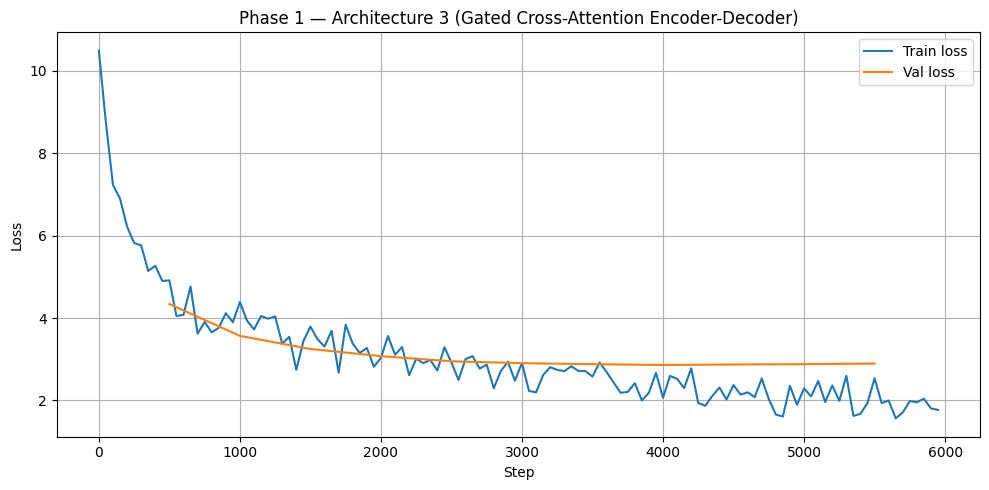

In [10]:
# %% [7] Plot loss curve
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 5))
plt.plot(history["step"], history["train_loss"], label="Train loss")
plt.plot(history["eval_step"], history["eval_loss"], label="Val loss")
plt.xlabel("Step"); plt.ylabel("Loss")
plt.title("Phase 1 — Architecture 3 (Gated Cross-Attention Encoder-Decoder)")
plt.legend(); plt.grid(True); plt.tight_layout()
plt.savefig(LOSS_PLOT_PATH, dpi=200)
plt.show()

In [11]:
# %% [8] Save checkpoint
torch.save({
    "model_state_dict": model.state_dict(),
    "config": dict(vocab_size=ACTUAL_VOCAB_SIZE, n_layer_enc=N_LAYER_ENC, n_layer_dec=N_LAYER_DEC,
                   n_head=N_HEAD, n_embd=N_EMBD, enc_len=ENC_LEN, dec_len=DEC_LEN,
                   ffn_mult=FFN_MULT, dropout=DROPOUT, pad_id=PAD_ID),
}, CKPT_PATH)
print("Saved checkpoint:", CKPT_PATH)

Saved checkpoint: /kaggle/working/cs781_phase1_arch3/model.pt


In [12]:
# %% [9] Generate 128-word continuations for the official test prompts
test_file_path = hf_hub_download(
    repo_id=HF_DATASET_REPO, filename=TEST_FILE, repo_type="dataset", token=HF_TOKEN
)
with open(test_file_path, "r", encoding="utf-8") as f:
    test_data = json.load(f)
print("Test examples:", len(test_data))

model.eval()
predictions = {}

for i, (example_id, record) in enumerate(test_data.items()):
    enc_ids = encode(record["text"], add_bos=True, add_eos=False)[:ENC_LEN]
    pad_len = ENC_LEN - len(enc_ids)
    enc_mask_list = [1] * len(enc_ids) + [0] * pad_len
    enc_ids = enc_ids + [PAD_ID] * pad_len

    enc_t = torch.tensor([enc_ids], dtype=torch.long, device=device)
    mask_t = torch.tensor([enc_mask_list], dtype=torch.bool, device=device)

    out = model.generate(enc_t, mask_t, max_new_tokens=DEC_LEN, bos_id=BOS_ID, eos_id=EOS_ID,
                          temperature=TEMPERATURE, top_p=TOP_P, no_repeat_ngram=NO_REPEAT_NGRAM)
    gen_ids = out[0, 1:].tolist()   # drop the leading BOS
    gen_text = decode(gen_ids)
    gen_words = gen_text.split()[:TARGET_GEN_WORDS]
    predictions[str(example_id)] = {"text": " ".join(gen_words)}
    if (i + 1) % 50 == 0:
        print(f"Generated {i+1}/{len(test_data)}")

# %% [10] Save prediction.json + zip for Codabench
with open(PREDICTION_PATH, "w", encoding="utf-8") as f:
    json.dump(predictions, f, ensure_ascii=False, indent=2)
with zipfile.ZipFile(SUBMISSION_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    zf.write(PREDICTION_PATH, arcname="prediction.json")
print("Codabench submission ready:", SUBMISSION_ZIP)

test.json: 0.00B [00:00, ?B/s]

Test examples: 1000
Generated 50/1000
Generated 100/1000
Generated 150/1000
Generated 200/1000
Generated 250/1000
Generated 300/1000
Generated 350/1000
Generated 400/1000
Generated 450/1000
Generated 500/1000
Generated 550/1000
Generated 600/1000
Generated 650/1000
Generated 700/1000
Generated 750/1000
Generated 800/1000
Generated 850/1000
Generated 900/1000
Generated 950/1000
Generated 1000/1000
Codabench submission ready: /kaggle/working/cs781_phase1_arch3/submission_phase1_arch3.zip
